# Team 7 · Monday: a material-finder autoencoder (MINC-2500)

**Team:** Ugo, Alvaro, Sneha · **Hackathon:** AI Methods I, 16–20 November 2026

**App idea:** a user uploads a photo of a surface (facade, floor, wall finish). The app returns the **5 most similar material patches**, a **material guess** and a warning if the photo looks **unusual** for a building material.

**Use of the autoencoder:** similarity search in latent space (main), anomaly score from the reconstruction error (bonus).

| Section | What happens |
|---|---|
| 1 | Load MINC-2500, keep 13 building materials, 64 × 64 RGB |
| 2 | Two architectures: dense AE and convolutional AE |
| 3 | Three setups on the same split and seed, one table (MSE + precision@5) |
| 4 | Similarity search: the proof figure, per-material quality, UMAP |
| 5 | Bonus: "unusual photo" score (building materials vs everything else) |
| 6 | Export for the model server: ONNX, config, gallery, examples |
| 7 | Conclusions (write them yourselves after the full run) |

**Data:** MINC-2500, Hugging Face mirror [`mcimpoi/minc-2500_split_1`](https://huggingface.co/datasets/mcimpoi/minc-2500_split_1), CC BY 4.0. Cite: Bell, Upchurch, Snavely and Bala (2015), *Material Recognition in the Wild with the Materials in Context Database*, CVPR.

**Before you run:** the parquet files must be in `data/minc-2500/data/` at the **root of the repository** (git-ignored). Download once with:

```bash
hf download mcimpoi/minc-2500_split_1 --repo-type dataset --local-dir data/minc-2500
```

In [40]:
# Only needed in Google Colab or a new environment: remove the "#" and run once.
# %pip install torch torchvision polars pillow scikit-learn matplotlib umap-learn onnx onnxscript onnxruntime

In [41]:
import io
import json
import os
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import torch
from PIL import Image
from sklearn.metrics import roc_auc_score, precision_score, recall_score
from sklearn.neighbors import NearestNeighbors
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# --- Folders (relative paths: this notebook lives in 01_autoencoder/notebook/) ---
AE_DIR = Path("..")                       # 01_autoencoder/
REPO_DIR = AE_DIR / ".."                  # repository root
DATA_DIR = REPO_DIR / "data"              # git-ignored
MINC_DIR = DATA_DIR / "minc-2500" / "data"
FIG_DIR = AE_DIR / "figures"
MODEL_DIR = AE_DIR / "models"             # goes to Hugging Face (model card, ONNX, gallery)
APP_DIR = AE_DIR / "model_app"            # what the Tuesday server needs
for folder in [FIG_DIR, MODEL_DIR, APP_DIR / "examples"]:
    folder.mkdir(parents=True, exist_ok=True)

# QUICK mode: a small subset and 1 epoch, to test that the notebook runs end to end.
# For the real run leave it off (MINC_QUICK not set).
QUICK = os.environ.get("MINC_QUICK") == "1"

IMAGE_SIZE = 64
RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
pd.set_option("display.float_format", "{:,.4f}".format)
print(f"PyTorch {torch.__version__}, device: {DEVICE}, QUICK mode: {QUICK}")
print("parquet files:", sorted(p.name for p in MINC_DIR.glob("*.parquet")))


def save_fig(name):
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

PyTorch 2.14.1, device: mps, QUICK mode: False
parquet files: ['test-00000-of-00001-9ca799ad09695eff.parquet', 'train-00000-of-00005-dbe3fdb3f07f1fda.parquet', 'train-00001-of-00005-5b231f26456ca063.parquet', 'train-00002-of-00005-c90a5ea07fbdddec.parquet', 'train-00003-of-00005-576d35d918cb64de.parquet', 'train-00004-of-00005-5a103631f553426a.parquet', 'validation-00000-of-00001-7984726e190ae40b.parquet']


# 1. The data

MINC-2500 has 23 classes of 2,500 patches each (362 × 362 px). We keep the **13 building materials** for training. The 10 other classes (food, foliage, sky, skin…) are never used for training: we only use their **test** patches in section 5, as examples of "not a building material".

**Split:** we use the train / validation / test split that comes with the dataset (split 1). The same split and seed for every setup.

**Preprocessing** (the server on Tuesday must do exactly the same, so it is one function):
1. convert to RGB;
2. centre-crop to a square (MINC patches are already square; user photos are not);
3. resize to 64 × 64 with bilinear filtering;
4. pixels 0–255 → 0–1, shape (3, 64, 64).

We keep the images as **uint8** in memory (4× less than float) and convert each batch when we use it.

In [42]:
ALL_CLASSES = ["brick", "carpet", "ceramic", "fabric", "foliage", "food", "glass", "hair", "leather",
               "metal", "mirror", "other", "painted", "paper", "plastic", "polishedstone", "skin", "sky",
               "stone", "tile", "wallpaper", "water", "wood"]          # label ids 0–22 (dataset card)
BUILDING = ["brick", "carpet", "ceramic", "glass", "metal", "mirror", "painted", "plastic",
            "polishedstone", "stone", "tile", "wallpaper", "wood"]
OTHER = [c for c in ALL_CLASSES if c not in BUILDING]
BUILDING_IDS = [ALL_CLASSES.index(c) for c in BUILDING]
OTHER_IDS = [ALL_CLASSES.index(c) for c in OTHER]
print(f"{len(BUILDING)} building materials, {len(OTHER)} other classes")


def preprocess(image: Image.Image) -> np.ndarray:
    # THE preprocessing, shared with the model server: RGB, centre square, 64 x 64, uint8 (H, W, 3)
    image = image.convert("RGB")
    w, h = image.size
    side = min(w, h)
    left, top = (w - side) // 2, (h - side) // 2
    image = image.crop((left, top, left + side, top + side))
    image = image.resize((IMAGE_SIZE, IMAGE_SIZE), Image.BILINEAR)
    return np.asarray(image, dtype=np.uint8)


def load_split(split, label_ids, per_class=None):
    # Read one split from the parquet files, keep some classes, decode and preprocess every image.
    files = sorted(MINC_DIR.glob(f"{split}-*.parquet"))
    assert files, f"No parquet files for '{split}' in {MINC_DIR}. Download the data first."
    df = (pl.scan_parquet(files)
          .select(pl.col("image").struct.field("bytes").alias("bytes"), pl.col("label"))
          .filter(pl.col("label").is_in(label_ids))
          .collect())
    if per_class:
        df = df.group_by("label", maintain_order=True).head(per_class)
    X = np.stack([preprocess(Image.open(io.BytesIO(b))) for b in df["bytes"]])
    return X, df["label"].to_numpy()


def load_cached(split, label_ids, name, per_class=None):
    # Decoding ~30,000 JPEGs takes a minute or two: do it once and keep a cache in data/ (git-ignored)
    cache = DATA_DIR / f"minc64_{name}{'_quick' if QUICK else ''}.npz"
    if cache.exists():
        d = np.load(cache)
        return d["X"], d["y"]
    start = time.time()
    X, y = load_split(split, label_ids, per_class)
    np.savez(cache, X=X, y=y)
    print(f"{split}/{name}: decoded {len(X):,} images in {time.time() - start:.0f} s -> {cache.name}")
    return X, y


PER_CLASS = 200 if QUICK else None          # QUICK: 200 images per class
remap = {orig: new for new, orig in enumerate(BUILDING_IDS)}   # original id -> 0..12

X_train_u8, y_train_orig = load_cached("train", BUILDING_IDS, "train", PER_CLASS)
X_val_u8, y_val_orig = load_cached("validation", BUILDING_IDS, "val", PER_CLASS and PER_CLASS // 4)
X_test_u8, y_test_orig = load_cached("test", BUILDING_IDS, "test", PER_CLASS and PER_CLASS // 4)
X_other_u8, y_other_orig = load_cached("test", OTHER_IDS, "test_other", PER_CLASS and PER_CLASS // 4)

y_train = np.array([remap[v] for v in y_train_orig])
y_val = np.array([remap[v] for v in y_val_orig])
y_test = np.array([remap[v] for v in y_test_orig])

print(f"train {X_train_u8.shape} | validation {X_val_u8.shape} | test {X_test_u8.shape} | "
      f"other-class test {X_other_u8.shape}")
pd.Series(np.bincount(y_train, minlength=len(BUILDING)), index=BUILDING, name="train patches").to_frame().T

13 building materials, 10 other classes
train (27625, 64, 64, 3) | validation (1625, 64, 64, 3) | test (3250, 64, 64, 3) | other-class test (2500, 64, 64, 3)


,brick,carpet,ceramic,glass,metal,mirror,painted,plastic,polishedstone,stone,tile,wallpaper,wood
train patches,2125,2125,2125,2125,2125,2125,2125,2125,2125,2125,2125,2125,2125


Figure saved to ../figures/01_samples.png


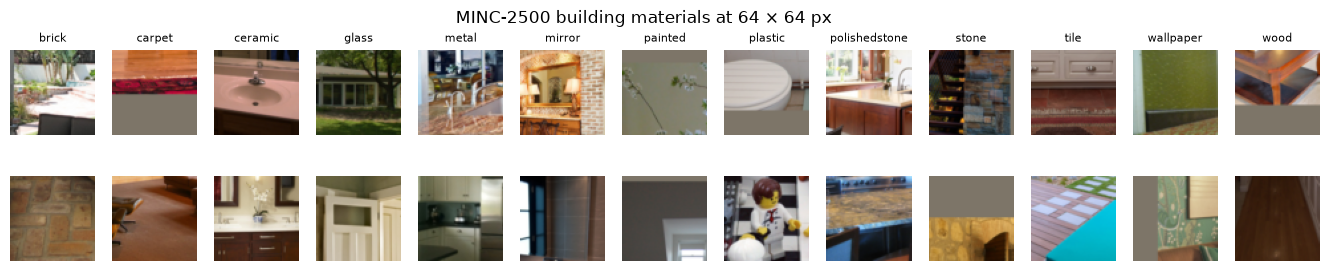

In [43]:
# Two example patches per building material, as the model sees them (64 x 64)
fig, axes = plt.subplots(2, len(BUILDING), figsize=(len(BUILDING) * 1.3, 3))
for k, name in enumerate(BUILDING):
    idx = np.flatnonzero(y_train == k)[:2]
    for row, i in enumerate(idx):
        axes[row, k].imshow(X_train_u8[i])
        axes[row, k].axis("off")
    axes[0, k].set_title(name, fontsize=8)
plt.suptitle("MINC-2500 building materials at 64 × 64 px")
save_fig("01_samples")
plt.show()

In [44]:
# uint8 (N, H, W, 3) -> torch uint8 (N, 3, H, W). Batches become floats 0-1 only when used.
def to_tensor(X_u8):
    return torch.from_numpy(X_u8).permute(0, 3, 1, 2).contiguous()


def to_float(batch_u8):
    return batch_u8.float().div(255)


X_train = to_tensor(X_train_u8)
X_val = to_tensor(X_val_u8)
X_test = to_tensor(X_test_u8)
X_other = to_tensor(X_other_u8)
print(X_train.shape, X_train.dtype)

torch.Size([27625, 3, 64, 64]) torch.uint8


# 2. Two architectures

- **DenseAE:** flattens the 64 × 64 × 3 = 12,288 numbers and squeezes them through a hidden layer of 256 to the code. It ignores that neighbouring pixels belong together: our baseline.
- **ConvAE:** three stride-2 convolutions halve the image 64 → 32 → 16 → 8, then a linear layer makes the code. The decoder mirrors it with transposed convolutions. A `Sigmoid` at the end keeps the output pixels in 0–1.

Both have an `encoder` (image → code) and a `decoder` (code → image). The **code** (latent vector) is what we use for similarity search.

In [45]:
class DenseAE(nn.Module):
    def __init__(self, latent_dim=64, hidden=256):
        super().__init__()
        n = 3 * IMAGE_SIZE * IMAGE_SIZE
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(n, hidden), nn.ReLU(), nn.Linear(hidden, latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim, hidden), nn.ReLU(), nn.Linear(hidden, n), nn.Sigmoid(),
                                     nn.Unflatten(1, (3, IMAGE_SIZE, IMAGE_SIZE)))

    def forward(self, x):
        return self.decoder(self.encoder(x))


class ConvAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.latent_dim = latent_dim
        s = IMAGE_SIZE // 8                                                   # 64 -> 8
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 4, stride=2, padding=1), nn.ReLU(),            # 64 -> 32
            nn.Conv2d(32, 64, 4, stride=2, padding=1), nn.ReLU(),           # 32 -> 16
            nn.Conv2d(64, 128, 4, stride=2, padding=1), nn.ReLU(),          # 16 -> 8
            nn.Flatten(),
            nn.Linear(128 * s * s, latent_dim),                              # the code
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128 * s * s), nn.ReLU(),
            nn.Unflatten(1, (128, s, s)),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.ReLU(),  # 8 -> 16
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1), nn.ReLU(),   # 16 -> 32
            nn.ConvTranspose2d(32, 3, 4, stride=2, padding=1), nn.Sigmoid(), # 32 -> 64
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


def n_params(model):
    return sum(p.numel() for p in model.parameters())


for m in [DenseAE(64), ConvAE(32), ConvAE(128)]:
    out = m(torch.zeros(2, 3, IMAGE_SIZE, IMAGE_SIZE))
    print(f"{type(m).__name__:8s} latent {m.latent_dim:4d}: {n_params(m):>10,} parameters, output {tuple(out.shape)}")

DenseAE  latent   64:  6,337,088 parameters, output (2, 3, 64, 64)
ConvAE   latent   32:    863,587 parameters, output (2, 3, 64, 64)
ConvAE   latent  128:  2,436,547 parameters, output (2, 3, 64, 64)


In [46]:
def train_autoencoder(model, X_train, X_val, epochs=12, lr=1e-3, batch_size=128, verbose=True):
    # Train an autoencoder to rebuild its input (MSE). X_* are uint8 tensors (N, 3, H, W).
    torch.manual_seed(RANDOM_STATE)
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X_train), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(RANDOM_STATE))
    history = []
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for (batch,) in loader:
            x = to_float(batch).to(DEVICE)
            loss = nn.functional.mse_loss(model(x), x)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(x)
        val_mse = reconstruction_error(model, X_val).mean().item()
        history.append({"epoch": epoch, "train_loss": total / len(X_train), "val_mse": val_mse})
        if verbose:
            print(f"epoch {epoch:2d}  train loss {total / len(X_train):.5f}  validation MSE {val_mse:.5f}")
    seconds = time.time() - start
    print(f"trained in {seconds:.0f} s")
    return model, pd.DataFrame(history), seconds


@torch.no_grad()
def reconstruction_error(model, X, batch_size=500):
    # One number per image: mean squared difference between input and output
    model.eval()
    errors = []
    for i in range(0, len(X), batch_size):
        x = to_float(X[i:i + batch_size]).to(DEVICE)
        errors.append(((model(x) - x) ** 2).mean(dim=(1, 2, 3)).cpu())
    return torch.cat(errors)


@torch.no_grad()
def reconstruct(model, X, batch_size=500):
    model.eval()
    return torch.cat([model(to_float(X[i:i + batch_size]).to(DEVICE)).cpu() for i in range(0, len(X), batch_size)])


@torch.no_grad()
def encode(model, X, batch_size=500):
    # Images -> latent codes (numpy, N x latent_dim)
    model.eval()
    return torch.cat([model.encoder(to_float(X[i:i + batch_size]).to(DEVICE)).cpu()
                      for i in range(0, len(X), batch_size)]).numpy()


def precision_at_k(Z_gallery, y_gallery, Z_query, y_query, k=5):
    # Share of the k nearest gallery codes that have the same material as the query.
    # The AE never saw the labels: this measures whether its latent space groups materials.
    nn_index = NearestNeighbors(n_neighbors=k).fit(Z_gallery)
    _, idx = nn_index.kneighbors(Z_query)
    hits = y_gallery[idx] == y_query[:, None]
    return hits.mean(), hits.mean(axis=1)

# 3. Three setups, one table

All setups use the same split, seed, number of epochs and learning rate.

| Setup | Question it answers |
|---|---|
| Dense AE, latent 64 | Baseline: what do we lose without convolutions? |
| Conv AE, latent 32 | Is a small, fast code good enough? |
| Conv AE, latent 128 | Does a bigger code rebuild better **and** find better neighbours? |

Columns: parameters, training time, validation and test MSE, and **precision@5**: for each test patch, the share of its 5 nearest **training** patches (in latent space) with the same material. Random guessing gives 1/13 ≈ 0.077.

⏱️ On a laptop CPU the full run takes a while (the conv models are the slow part). With a GPU or Apple MPS it is much faster.

In [47]:
EPOCHS = 1 if QUICK else 12
SETUPS = [
    ("dense AE, latent 64", lambda: DenseAE(latent_dim=64)),
    ("conv AE, latent 32", lambda: ConvAE(latent_dim=32)),
    ("conv AE, latent 128", lambda: ConvAE(latent_dim=128)),
]

models, histories, rows = {}, {}, []
for name, make in SETUPS:
    print(f"\n=== {name} ===")
    model, history, seconds = train_autoencoder(make(), X_train, X_val, epochs=EPOCHS)
    Z_tr, Z_te = encode(model, X_train), encode(model, X_test)
    p5, _ = precision_at_k(Z_tr, y_train, Z_te, y_test, k=5)
    models[name], histories[name] = model, history
    rows.append({
        "setup": name,
        "parameters": n_params(model),
        "train time (s)": round(seconds),
        "val MSE": reconstruction_error(model, X_val).mean().item(),
        "test MSE": reconstruction_error(model, X_test).mean().item(),
        "precision@5": p5,
    })

results = pd.DataFrame(rows).set_index("setup")
results.to_csv(AE_DIR / "results_table.csv")
results


=== dense AE, latent 64 ===
epoch  1  train loss 0.03249  validation MSE 0.02317
epoch  2  train loss 0.02046  validation MSE 0.02013
epoch  3  train loss 0.01960  validation MSE 0.02030
epoch  4  train loss 0.01949  validation MSE 0.02000
epoch  5  train loss 0.01943  validation MSE 0.01997
epoch  6  train loss 0.01932  validation MSE 0.01977
epoch  7  train loss 0.01870  validation MSE 0.01897
epoch  8  train loss 0.01848  validation MSE 0.01881
epoch  9  train loss 0.01846  validation MSE 0.01879
epoch 10  train loss 0.01843  validation MSE 0.01886
epoch 11  train loss 0.01839  validation MSE 0.01878
epoch 12  train loss 0.01838  validation MSE 0.01903
trained in 25 s

=== conv AE, latent 32 ===
epoch  1  train loss 0.03602  validation MSE 0.01722
epoch  2  train loss 0.01445  validation MSE 0.01288
epoch  3  train loss 0.01192  validation MSE 0.01142
epoch  4  train loss 0.01096  validation MSE 0.01113
epoch  5  train loss 0.01059  validation MSE 0.01070
epoch  6  train loss 0.010

,parameters,train time (s),val MSE,test MSE,precision@5
setup,,,,,
"dense AE, latent 64",6337088,25,0.0190,0.0188,0.1286
"conv AE, latent 32",863587,76,0.0105,0.0104,0.1399
"conv AE, latent 128",2436547,82,0.0053,0.0052,0.1297


Figure saved to ../figures/02_training_curves.png


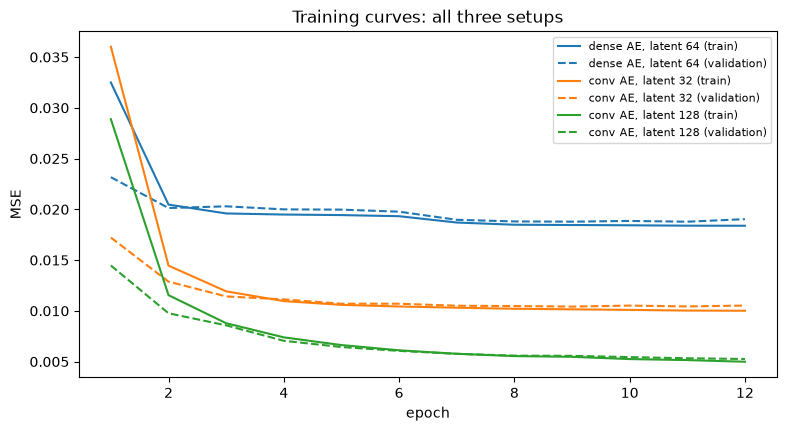

In [48]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, h in histories.items():
    line, = ax.plot(h["epoch"], h["train_loss"], label=f"{name} (train)")
    ax.plot(h["epoch"], h["val_mse"], "--", color=line.get_color(), label=f"{name} (validation)")
ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.set_title("Training curves: all three setups")
ax.legend(fontsize=8)
save_fig("02_training_curves")
plt.show()

chosen setup: conv AE, latent 32
Figure saved to ../figures/03_reconstructions.png


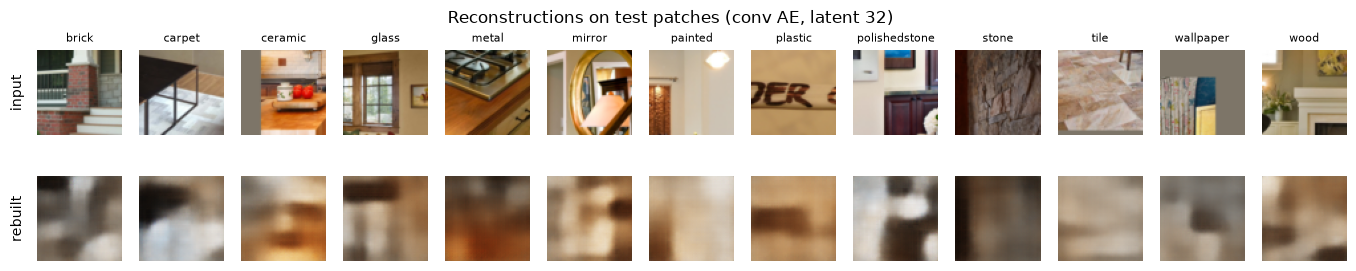

In [49]:
# Which setup goes to the app? The app's job is similarity search, so we pick the best precision@5.
BEST = results["precision@5"].idxmax()
model = models[BEST].to(DEVICE)
print("chosen setup:", BEST)

idx = np.concatenate([np.flatnonzero(y_test == k)[:1] for k in range(len(BUILDING))])
rebuilt = reconstruct(model, X_test[idx])
fig, axes = plt.subplots(2, len(idx), figsize=(len(idx) * 1.3, 3))
for j, i in enumerate(idx):
    axes[0, j].imshow(X_test_u8[i]); axes[0, j].set_title(BUILDING[y_test[i]], fontsize=8)
    axes[1, j].imshow(rebuilt[j].permute(1, 2, 0).numpy())
    axes[0, j].axis("off"); axes[1, j].axis("off")
axes[0, 0].text(-10, 32, "input", rotation=90, va="center", ha="right")
axes[1, 0].text(-10, 32, "rebuilt", rotation=90, va="center", ha="right")
plt.suptitle(f"Reconstructions on test patches ({BEST})")
save_fig("03_reconstructions")
plt.show()

**✍️ Your conclusion on the table (write it after the full run, not before):**
- Best reconstruction vs best neighbours: not the same setup. The conv AE with latent 128 rebuilds best (test MSE 0.0052), about half the error of conv latent 32 (0.0104). It is also much better than the dense AE (0.0188). But conv latent 32 finds the best neighbours (precision@5 0.140, vs 0.130 for latent 128 and 0.129 for dense). A bigger code stores more of the photo’s layout and lighting, but that doesn’t help find the same material. This shows that rebuilding well and searching well are different goals.
- Compared with random: precision@5 of 0.140 is about 1.8× the random baseline (1/13 ≈ 0.077). The latent space has learned something about materials without ever seeing a label, but on average fewer than 1 of the 5 matches is the right material. Search works best for painted, wallpaper and carpet (about 0.23–0.25). It is no better than chance for metal and plastic.
- What the reconstructions keep and lose: they keep the overall colour, brightness and the rough layout of the patch (light and dark areas, large shapes). They lose all fine texture: brick joints, wood grain, tile edges and carpet fibres become smooth blurs. So the code describes “a brown, dark-on-the-left image” more than “wood”. This explains why search mixes up materials with similar colours, and why patches with the same grey padding get matched together.
- Was the bigger model worth it?
    - Dense vs conv 32: the conv 32 model is clearly better. It has 7× fewer parameters (0.86 M vs 6.3 M), lower error and better search. It takes about 3× longer to train (76 s vs 24 s), which still doesn’t matter at this size.
    - Conv 32 vs conv 128: latent 128 costs 2.8× more parameters (2.4 M) for a better redraw, but slightly worse search. For our app, whose job is “find similar”, it isn’t worth it.
So we chose conv AE, latent 32. It is also the smallest model (3.5 MB ONNX file), which suits the free Render server.

# 4. Similarity search: does "find similar" work?

This is the engine of the app: encode a collection once, store the codes, and for a new photo compute its code and return the closest stored ones.

**Proof figure:** a query test patch, then its 5 nearest training patches with their material and distance.

Figure saved to ../figures/04_similarity_search.png


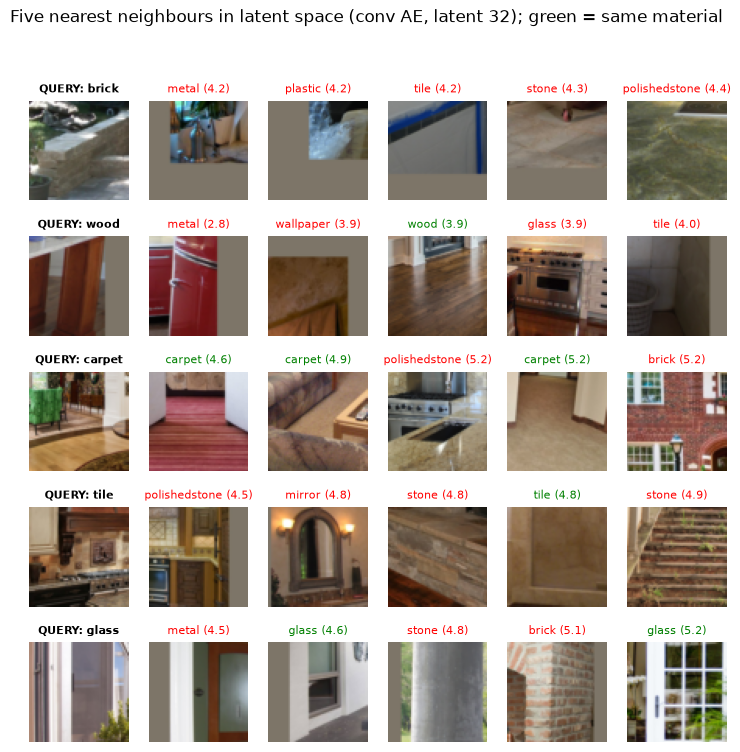

median distance to the 5 neighbours: 4.56 | between two random patches: 8.97


In [50]:
Z_train = encode(model, X_train)
Z_test = encode(model, X_test)
index = NearestNeighbors(n_neighbors=5).fit(Z_train)

SHOW = ["brick", "wood", "carpet", "tile", "glass"]
queries = [int(np.flatnonzero(y_test == BUILDING.index(m))[3]) for m in SHOW]
dist, nbr = index.kneighbors(Z_test[queries])

fig, axes = plt.subplots(len(SHOW), 6, figsize=(9, 1.7 * len(SHOW)))
for r, q in enumerate(queries):
    axes[r, 0].imshow(X_test_u8[q]); axes[r, 0].set_title(f"QUERY: {BUILDING[y_test[q]]}", fontsize=8, fontweight="bold")
    for c in range(5):
        i = nbr[r, c]
        same = y_train[i] == y_test[q]
        axes[r, c + 1].imshow(X_train_u8[i])
        axes[r, c + 1].set_title(f"{BUILDING[y_train[i]]} ({dist[r, c]:.1f})", fontsize=8,
                                 color="green" if same else "red")
    for a in axes[r]:
        a.axis("off")
plt.suptitle(f"Five nearest neighbours in latent space ({BEST}); green = same material")
save_fig("04_similarity_search")
plt.show()

random_pairs = rng.integers(0, len(Z_train), size=(2000, 2))
median_random = np.median(np.linalg.norm(Z_train[random_pairs[:, 0]] - Z_train[random_pairs[:, 1]], axis=1))
print(f"median distance to the 5 neighbours: {np.median(dist):.2f} | between two random patches: {median_random:.2f}")

Figure saved to ../figures/05_precision_per_material.png


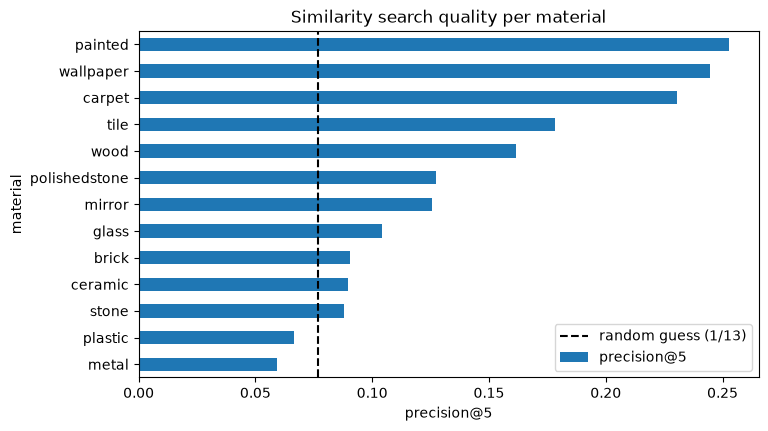

material,metal,plastic,stone,ceramic,brick,glass,mirror,polishedstone,wood,tile,carpet,wallpaper,painted
precision@5,0.0592,0.0664,0.0880,0.0896,0.0904,0.1040,0.1256,0.1272,0.1616,0.1784,0.2304,0.2448,0.2528


In [51]:
# Which materials does the latent space recognise, and which does it confuse?
_, per_query = precision_at_k(Z_train, y_train, Z_test, y_test, k=5)
per_material = (pd.DataFrame({"material": [BUILDING[k] for k in y_test], "precision@5": per_query})
                .groupby("material")["precision@5"].mean().sort_values())

fig, ax = plt.subplots(figsize=(8, 4.5))
per_material.plot.barh(ax=ax, color="tab:blue")
ax.axvline(1 / len(BUILDING), color="black", linestyle="--", label="random guess (1/13)")
ax.set_xlabel("precision@5"); ax.set_title("Similarity search quality per material"); ax.legend()
save_fig("05_precision_per_material")
plt.show()
per_material.to_frame().T

/Users/snehashenoy/Downloads/group7_day1_assigment/hackathon-team7-MINC_2500_material_patches/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Figure saved to ../figures/06_latent_umap.png


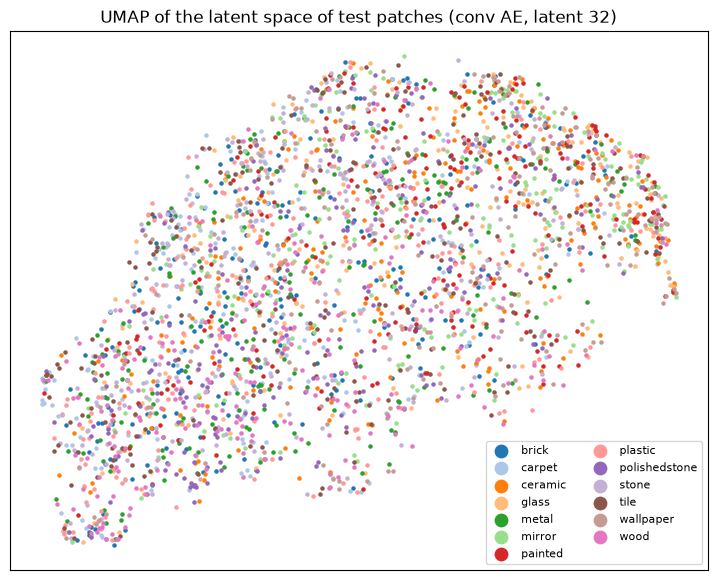

In [52]:
# A 2D map of the latent space (UMAP), coloured by material. The colours are NOT used by the model.
try:
    import umap
    sub = rng.choice(len(Z_test), size=min(3000, len(Z_test)), replace=False)
    xy = umap.UMAP(random_state=RANDOM_STATE).fit_transform(Z_test[sub])
    fig, ax = plt.subplots(figsize=(9, 7))
    cmap = plt.get_cmap("tab20")
    for k, name in enumerate(BUILDING):
        m = y_test[sub] == k
        ax.scatter(xy[m, 0], xy[m, 1], s=5, color=cmap(k), label=name)
    ax.legend(markerscale=4, fontsize=8, ncol=2); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"UMAP of the latent space of test patches ({BEST})")
    save_fig("06_latent_umap")
    plt.show()
except ImportError:
    print("umap-learn is not installed: skip this figure (pip install umap-learn)")

# 5. Bonus: an "unusual photo" score

The app should warn when a photo is not a building-material surface at all (a face, a plate of food, the sky). The autoencoder was trained only on building materials, so it should rebuild those better than anything else.

1. The **threshold** is the 95th percentile of the reconstruction error on **validation** building patches: about 5% false alarms by design.
2. We test it **once** on test patches: building materials (normal) vs the 10 other MINC classes (unusual), which the model never saw.

threshold 0.02417
ROC AUC   0.648  (0.5 = no better than chance)
precision 0.612  recall 0.108
Figure saved to ../figures/07_unusual_histogram.png


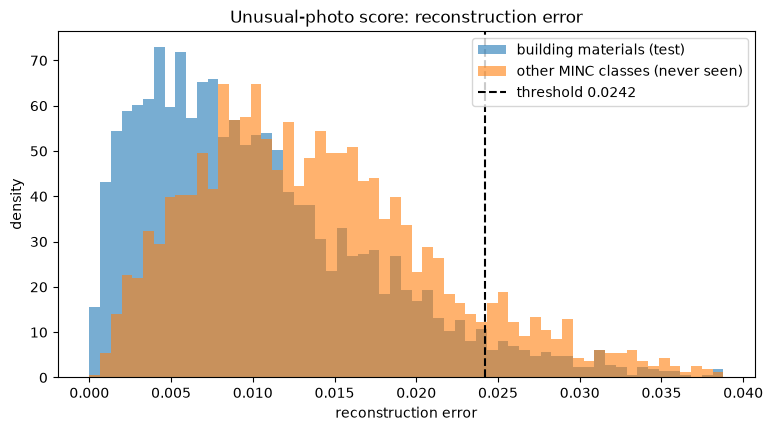

,mean_error,flagged
class,,
sky,0.0098,0.0200
fabric,0.0123,0.0840
hair,0.0127,0.0800
leather,0.0128,0.0760
skin,0.0144,0.1200
water,0.0146,0.1120
foliage,0.0150,0.1080
other,0.0154,0.1320
paper,0.0158,0.1880


In [53]:
val_errors = reconstruction_error(model, X_val).numpy()
THRESHOLD = float(np.quantile(val_errors, 0.95))

err_building = reconstruction_error(model, X_test).numpy()
err_other = reconstruction_error(model, X_other).numpy()
scores = np.concatenate([err_building, err_other])
is_unusual = np.concatenate([np.zeros(len(err_building)), np.ones(len(err_other))]).astype(int)
flagged = (scores > THRESHOLD).astype(int)

UNUSUAL_AUC = roc_auc_score(is_unusual, scores)
print(f"threshold {THRESHOLD:.5f}")
print(f"ROC AUC   {UNUSUAL_AUC:.3f}  (0.5 = no better than chance)")
print(f"precision {precision_score(is_unusual, flagged):.3f}  recall {recall_score(is_unusual, flagged):.3f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.linspace(0, np.quantile(scores, 0.995), 60)
ax.hist(err_building, bins=bins, alpha=0.6, density=True, label="building materials (test)")
ax.hist(err_other, bins=bins, alpha=0.6, density=True, label="other MINC classes (never seen)")
ax.axvline(THRESHOLD, color="black", linestyle="--", label=f"threshold {THRESHOLD:.4f}")
ax.set_xlabel("reconstruction error"); ax.set_ylabel("density"); ax.legend()
ax.set_title("Unusual-photo score: reconstruction error")
save_fig("07_unusual_histogram")
plt.show()

other_names = [ALL_CLASSES[v] for v in y_other_orig]
(pd.DataFrame({"class": other_names, "error": err_other, "flagged": flagged[len(err_building):]})
   .groupby("class").agg(mean_error=("error", "mean"), flagged=("flagged", "mean")).sort_values("mean_error"))

The score is weak.

ROC AUC is 0.65. On 0.5 (chance) to 1.0 (perfect), that is only a bit better than chance. The two histograms in figure 07 overlap almost completely.
The 95% threshold (0.0242) misses most unusual photos.
It catches only 11% of them (recall 0.108).
Of the photos it flags, only 61% really are unusual (precision 0.61).
It also flags 5.3% of normal building patches, which matches the 95% rule.

Why: reconstruction error measures how hard a picture is to redraw, not what it shows. The per-class errors make this clear:

| What happened	| Classes (mean error, share flagged) | 
|---|---|
| Smooth photos slip through |	**sky** (0.0098, 2% flagged) is rebuilt more easily than wood or brick, so a sky photo looks “normal” |
| Busy or messy photos stand out a bit |	**food** (0.0170, 16%), paper (0.0158, 19%), foliage (0.0150, 11%), “other” (0.0154, 13%) |
| Some never-seen classes look normal |**hair** (0.0127, 8%), leather and fabric (about 0.0125, 8%) score like building materials |
| Some building materials look unusual |	**glass** (0.0144, 11% flagged) and plastic (0.0135, 10%) are as hard to rebuild as water or foliage, because glass shows whatever is behind it |
| Flat building materials are easiest |	**painted** (0.0062), tile, carpet, wallpaper: smooth, even surfaces |

# 6. Export for the model server (Tuesday)

The server needs:

| File | Where | What |
|---|---|---|
| `material_ae.onnx` | `models/` and `model_app/` | image → **(reconstruction, code)** in one call |
| `config.json` | `models/` and `model_app/` | preprocessing, sizes, classes, threshold, results |
| `gallery_latents.npy` | `models/` | codes of the gallery patches (what we search in) |
| `gallery_meta.json` | `models/` | id and material of each gallery patch |
| `gallery_thumbs/*.jpg` | `models/` | the 64 px thumbnails the app shows |
| `examples/*.jpg` | `model_app/` | a few test photos for the server page |

`models/` goes to Hugging Face. `*.onnx` and `*.npy` are git-ignored, so the Render server **downloads them from Hugging Face** at startup.

In [54]:
class MaterialAE(nn.Module):
    # Wrapper for export: one call returns the reconstruction (for the unusual score) and the code (for search)
    def __init__(self, ae):
        super().__init__()
        self.ae = ae

    def forward(self, image):
        code = self.ae.encoder(image)
        return self.ae.decoder(code), code


export_model = MaterialAE(models[BEST].cpu().eval()).eval()
example_input = to_float(X_test[:1])
onnx_path = MODEL_DIR / "material_ae.onnx"
torch.onnx.export(export_model, (example_input,), onnx_path,
                  input_names=["image"], output_names=["reconstruction", "code"],
                  dynamic_shapes={"image": {0: torch.export.Dim("batch")}}, external_data=False, verbose=False)
shutil.copy(onnx_path, APP_DIR / "material_ae.onnx")
torch.save(models[BEST].state_dict(), MODEL_DIR / "material_ae.pt")
print(f"{onnx_path}: {onnx_path.stat().st_size / 1e6:.1f} MB")

../models/material_ae.onnx: 3.5 MB


In [55]:
# The gallery: a balanced sample of training patches the app searches in
GALLERY_PER_CLASS = 20 if QUICK else 300
gallery_idx = np.concatenate([rng.choice(np.flatnonzero(y_train == k), size=GALLERY_PER_CLASS, replace=False)
                              for k in range(len(BUILDING))])
Z_gallery = encode(models[BEST].to(DEVICE), X_train[gallery_idx]).astype(np.float32)
np.save(MODEL_DIR / "gallery_latents.npy", Z_gallery)

thumb_dir = MODEL_DIR / "gallery_thumbs"
thumb_dir.mkdir(exist_ok=True)
meta = []
for gid, i in enumerate(gallery_idx):
    Image.fromarray(X_train_u8[i]).save(thumb_dir / f"{gid:05d}.jpg", quality=90)
    meta.append({"id": gid, "material": BUILDING[y_train[i]], "thumb": f"gallery_thumbs/{gid:05d}.jpg"})
(MODEL_DIR / "gallery_meta.json").write_text(json.dumps(meta))

# How good is search in this smaller gallery (the one the app really uses)?
p5_gallery, _ = precision_at_k(Z_gallery, y_train[gallery_idx], encode(model, X_test), y_test, k=5)
print(f"gallery: {len(gallery_idx):,} patches, codes {Z_gallery.shape}, precision@5 in the gallery {p5_gallery:.3f}")

gallery: 3,900 patches, codes (3900, 32), precision@5 in the gallery 0.126


In [56]:
config = {
    "model": "material_ae.onnx",
    "setup": BEST,
    "latent_dim": int(models[BEST].latent_dim),
    "image_size": IMAGE_SIZE,
    "preprocessing": "RGB, centre-crop to a square, resize to 64x64 (PIL bilinear), pixels / 255 -> 0-1, "
                     "shape (1, 3, 64, 64) float32",
    "inputs": {"image": "float32 (batch, 3, 64, 64), values 0-1"},
    "outputs": {"reconstruction": "float32 (batch, 3, 64, 64)", "code": "float32 (batch, latent_dim)"},
    "classes": BUILDING,
    "similarity": "Euclidean distance between codes; top 5 gallery patches; material guess = majority vote",
    "gallery_size": int(len(gallery_idx)),
    "unusual_threshold": THRESHOLD,
    "unusual_threshold_rule": "95th percentile of the reconstruction error on validation building patches",
    "results": {
        "test_mse": float(results.loc[BEST, "test MSE"]),
        "precision_at_5_full_train": float(results.loc[BEST, "precision@5"]),
        "precision_at_5_gallery": float(p5_gallery),
        "unusual_roc_auc": float(UNUSUAL_AUC),
    },
    "dataset": "MINC-2500 (mcimpoi/minc-2500_split_1), CC BY 4.0, Bell et al. 2015 CVPR",
    "quick_mode": QUICK,
}
for folder in [MODEL_DIR, APP_DIR]:
    (folder / "config.json").write_text(json.dumps(config, indent=2))

# Example inputs for the server page: original 362 px test patches (not our 64 px copies)
test_files = sorted(MINC_DIR.glob("test-*.parquet"))
for name in ["brick", "wood", "tile", "carpet"]:
    row = (pl.scan_parquet(test_files).filter(pl.col("label") == ALL_CLASSES.index(name))
           .select(pl.col("image").struct.field("bytes")).head(1).collect())
    Image.open(io.BytesIO(row.item())).convert("RGB").save(APP_DIR / "examples" / f"{name}.jpg", quality=92)

# The model card on Hugging Face needs the figures next to it
shutil.copytree(FIG_DIR, MODEL_DIR / "figures", dirs_exist_ok=True)
for p in sorted(APP_DIR.rglob("*.*")):
    print(f"{str(p):45s} {p.stat().st_size / 1024:9.1f} KB")

../model_app/config.json                            1.2 KB
../model_app/examples/brick.jpg                    29.1 KB
../model_app/examples/carpet.jpg                   33.5 KB
../model_app/examples/tile.jpg                     28.9 KB
../model_app/examples/wood.jpg                     27.0 KB
../model_app/material_ae.onnx                    3401.9 KB


In [57]:
export_model = export_model.cpu()

In [58]:
# Check: ONNX Runtime gives the same codes and reconstructions as PyTorch,
# and the full path (photo file -> preprocess -> ONNX -> nearest gallery patches) works like the server will.
import onnxruntime as ort

session = ort.InferenceSession(str(APP_DIR / "material_ae.onnx"))
batch = to_float(X_test[:5])
onnx_rec, onnx_code = session.run(None, {"image": batch.numpy()})
with torch.no_grad():
    torch_rec, torch_code = export_model(batch)
print("same codes:          ", np.allclose(onnx_code, torch_code.numpy(), atol=1e-4))
print("same reconstructions:", np.allclose(onnx_rec, torch_rec.numpy(), atol=1e-4))

# What the server will do with an uploaded photo
photo = Image.open(APP_DIR / "examples" / "brick.jpg")
x = preprocess(photo).astype(np.float32).transpose(2, 0, 1)[None] / 255.0
rec, code_ = session.run(None, {"image": x})
d = np.linalg.norm(Z_gallery - code_, axis=1)
top = np.argsort(d)[:5]
votes = pd.Series([meta[i]["material"] for i in top]).value_counts()
print(f"brick.jpg -> guess '{votes.index[0]}' ({votes.iloc[0]}/5), unusual score "
      f"{float(((rec - x) ** 2).mean()):.5f} (threshold {THRESHOLD:.5f})")
print("top 5:", [(meta[i]["material"], round(float(d[i]), 2)) for i in top])

same codes:           True
same reconstructions: True
brick.jpg -> guess 'metal' (1/5), unusual score 0.01636 (threshold 0.02417)
top 5: [('metal', 5.0), ('wallpaper', 5.11), ('brick', 5.13), ('polishedstone', 5.13), ('stone', 5.22)]


# 7. Conclusions (write these yourselves)

**Key findings (from our full run: 12 epochs, 27,625 training patches, seed 42)**

The table:
- Convolutions beat dense layers. The conv AE with latent 32 halves the redraw error of the dense AE (test MSE 0.0104 vs 0.0188) with 7× fewer parameters (0.86 M vs 6.3 M).
- A bigger code rebuilds better but doesn’t search better. Latent 128 halves the error again (0.0052), but its precision@5 drops slightly (0.130 vs 0.140).
- We chose conv AE, latent 32: best search, smallest model (3.5 MB ONNX).
- All curves level off by about epoch 8, and validation follows training, so there is no overfitting.

Similarity search:
- precision@5 is 0.140 against 0.077 for random: about 1.8× chance, but fewer than 1 in 5 matches is the right material.
- Works best for even, coloured surfaces: painted (0.25), wallpaper (0.25), carpet (0.23), tile (0.18), wood (0.16).
- Fails for metal (0.06) and plastic (0.07), both below random. Brick, ceramic and stone are barely above it.
- In figure 04, many neighbours share the same grey padding block, not the same material.
Unusual score:

- ROC AUC 0.65, only a little better than chance. At the 95% threshold it catches 11% of unusual photos (recall 0.11, precision 0.61).
- Sky slips through easily (2% flagged): it is smoother than most building materials.
- Hair, leather and fabric also look “normal” (about 8% flagged).
- Food and paper stand out most (16–19%).
- Glass, a building material, scores as high as water or foliage.

**Limitations / where it fails:**

Colour, not material. A pixel autoencoder groups images by colour, brightness and rough layout. The reconstructions are blurry colour blobs with no texture: no brick joints, no wood grain.
Reflective and shiny materials. Metal, glass and mirror show their surroundings, and plastic comes in every colour, so their codes are scattered.
MINC patches are scenes, not close-ups. Each patch shows a whole room or facade, and the label only describes the material at the centre. The model learns the scene, not the surface.
Grey padding. Patches cut near the edge of the original photo have grey filled corners. The model matches on these blocks.
The unusual score measures difficulty, not content. It can’t tell sky from paint, so the app must show it as a hint, not a verdict.
Real user photos will differ again (phone cameras, lighting, angle). We haven’t tested our own photos yet.
